In [1]:
import pandas as pd
events = pd.read_csv(
    "/Users/dominik/Documents/GitHub/EBV/events_chunk.txt",
    sep=r"\s+",
    header=None,
    names=["timestamp", "x", "y", "polarity"],
)


In [2]:
from typing import Any
from numpy import double


first_ts:double = events['timestamp'].min()
last_ts:double = events['timestamp'].max()
dur:double = last_ts - first_ts
bins = 20
increment = dur/bins
counts: list[Any] = list()
for i in range(bins):
    df = events[events['timestamp'].between(i*increment, (i+1)*increment)]
    counts.append(len(df))
print(counts)

[661, 1507, 1788, 1816, 3109, 2034, 2212, 2399, 2567, 3489, 2547, 2791, 2582, 4144, 2486, 2531, 2307, 2440, 3304, 2187]


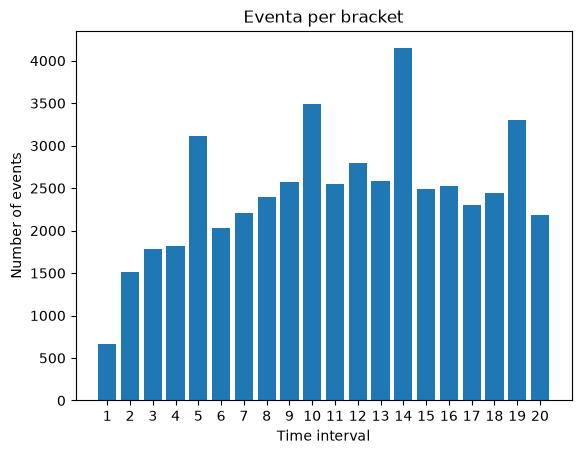

In [3]:
import matplotlib.pyplot as plt

plt.bar(range(1, len(counts) + 1), counts)
plt.xlabel("Time interval")
plt.ylabel("Number of events")
plt.title("Eventa per bracket")
plt.xticks(range(1, len(counts) + 1))
plt.show()

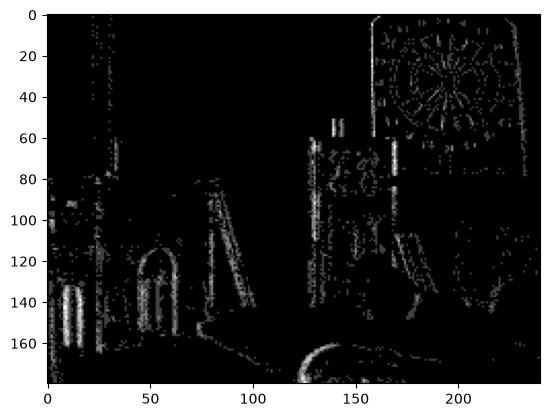

In [4]:
import numpy as np
def get_frame_from_range(start=0, end=5000):
    pic = np.zeros((180,240))
    frame_events = events.iloc[start:end]
    for i in range(len(frame_events)):
        x = int(frame_events.iloc[i]['x'])
        y = int(frame_events.iloc[i]['y'])
        pic[y,x] += 1
    return pic
# pic = np.zeros((180,240))
# first_events = events.iloc[:5000]
# for i in range(len(first_events)):
#     x = int(first_events.iloc[i]['x'])
#     y = int(first_events.iloc[i]['y'])
#     pic[y,x] += 1
first = get_frame_from_range()
plt.imshow(first, cmap='gray')
plt.show()


In [5]:
import cv2
from matplotlib.animation import ArtistAnimation
from IPython.display import HTML, display

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_title('Event Stream')
frames = []
for start in range(0, len(events)-5000+1, 1000):
    f = get_frame_from_range(start, start+5000)
    d = cv2.normalize(f, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    frames.append([ax.imshow(d, cmap='gray', vmin=0, vmax=255,
                             interpolation='nearest', animated=True)])

animation = ArtistAnimation(fig, frames, interval=30, repeat=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

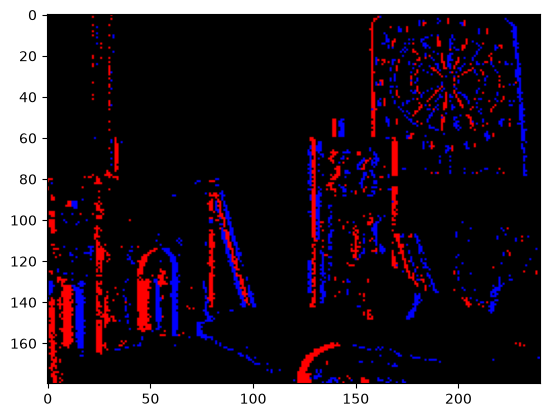

In [6]:
from numpy import uint8


def get_frame_from_range_rgb(start=0, end=5000, dest = 'rgb'):
    pic = np.zeros((180,240, 3), dtype = uint8)
    frame_events = events.iloc[start:end]
    for i in range(len(frame_events)):
        x = int(frame_events.iloc[i]['x'])
        y = int(frame_events.iloc[i]['y'])
        polarity = int(frame_events.iloc[i]['polarity'])
        if polarity == 1:
            if dest == 'rgb':
                pic[y,x] = [255, 0, 0]
            if dest == 'bgr':
                pic[y,x] = [0, 0, 255]
        if polarity == 0:
            if dest == 'rgb':
                pic[y,x] = [0, 0, 255]
            if dest == 'bgr':
                pic[y,x] = [255, 0, 0]
    return pic

color_pic = get_frame_from_range_rgb(dest = 'bgr')
plt.imshow(X=color_pic)


In [7]:
import cv2
from matplotlib.animation import ArtistAnimation
from IPython.display import HTML, display

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_title('Event Stream - polarity')
frames = []
for start in range(0, len(events)-5000+1, 1000):
    f = get_frame_from_range_rgb(start, start+5000, dest='rgb')
    d = cv2.normalize(f, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    frames.append([ax.imshow(d, interpolation='nearest', animated=True)])

animation = ArtistAnimation(fig, frames, interval=30, repeat=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

In [8]:
def resize(img, factor=3):
    import cv2
    return cv2.resize(img, None,
    fx=3, fy=3,
    interpolation=cv2.INTER_NEAREST
)


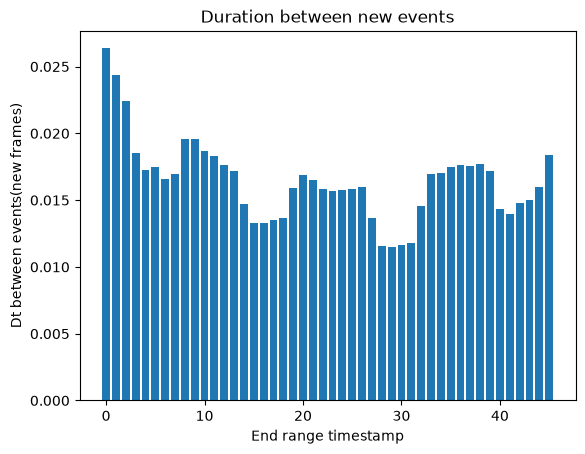

In [17]:
durations = list()
ending_timestamps = list()
for i in range(0, len(events)-5000+1, 1000):
    start = i
    end = start + 5000 - 1
    dur_events = events.iloc[end]['timestamp']-events.iloc[start]['timestamp'] 
    durations.append(dur_events)
    ending_timestamps.append(events.iloc[end]['timestamp'])

plt.bar(x=range(0, len(durations)), height=durations)
plt.xlabel("End range timestamp")
plt.ylabel("Dt between events(new frames)")
plt.title("Duration between new events")
plt.show()